# Análisis de Sentimientos de Twitter

**Fuente original:** https://www.geeksforgeeks.org/python/twitter-sentiment-analysis-using-python/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzua

---

El Análisis de Sentimiento en Twitter es el proceso de usar Python para entender automáticamente las emociones u opiniones expresadas en los tuits. Analizando el texto podemos clasificar los tuits como positivos, negativos o neutrales. Esto ayuda a empresas e investigadores a seguir el estado de ánimo público, la reputación de la marca o las reacciones a los acontecimientos en tiempo real. Bibliotecas de Python como TextBlob, Tweepy y NLTK facilitan la recopilación de tuits, el procesamiento del texto y el análisis de sentimiento de forma eficiente.

##¿Cómo es útil el análisis de sentimiento en Twitter?
El análisis de sentimiento en Twitter es importante porque ayuda a personas y empresas a entender lo que piensa el público en tiempo real.

Cada día se publican millones de tuits, compartiendo opiniones sobre marcas, productos, eventos o temas sociales. Al analizar este enorme flujo de datos, las empresas pueden medir la satisfacción del cliente, detectar tendencias desde el principio, gestionar rápidamente los comentarios negativos y tomar mejores decisiones basadas en cómo se sienten realmente las personas.

También es útil para investigadores y gobiernos monitorizar el ánimo público durante elecciones, crisis o grandes eventos, ya que convierte tuits en brutos en valiosos conocimientos.

##Implementación paso a paso

### 1. Instalar bibliotecas necesarias

In [2]:
!pip install pandas scikit-learn

In [3]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

###2: Cargar el conjunto de datos
Aquí cargamos el conjunto de datos Sentiment140 desde un archivo CSV comprimido, puedes descargarlo desde Kaggle.

Conservamos solo la polaridad y las columnas de texto de los tuits, las renombramos para mayor claridad e imprimimos las primeras filas para comprobar los datos.

In [4]:
"""from google.colab import files
uploaded= files.upload()"""

In [35]:
#CODIGO DE KAGGLE

import kagglehub

# Download latest version
path = kagglehub.dataset_download("kazanova/sentiment140")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'sentiment140' dataset.
Path to dataset files: /kaggle/input/sentiment140


In [36]:
import os

#Construir la ruta exacta al archivo CSV
#dentro de esa carpeta
csv_path = os.path.join(path, "training.1600000.processed.noemoticon.csv")


# Load Sentiment140 data
#df = pd.read_csv('training.1600000.processed.noemoticon.csv.zip', encoding='latin-1', header=None)
df = pd.read_csv(
    csv_path,
    encoding='latin-1',
    header=None
)
df = df[[0, 5]]
df.columns = ['polarity', 'text']
print(df.head())


   polarity                                               text
0         0  @switchfoot http://twitpic.com/2y1zl - Awww, t...
1         0  is upset that he can't update his Facebook by ...
2         0  @Kenichan I dived many times for the ball. Man...
3         0    my whole body feels itchy and like its on fire 
4         0  @nationwideclass no, it's not behaving at all....


###3: Guarda solo sentimientos positivos y negativos
Aquí eliminamos los tweets neutros donde la polaridad es 2, mapeamos las etiquetas para que 0 permanezca negativo y 4 se convierta en 1 para positivo.

Luego imprimimos cuántos tuits positivos y negativos quedan en los datos.

In [12]:
# Keep only positive (4) and negative (0)
df = df[df.polarity != 2]

df['polarity'] = df['polarity'].map({0: 0, 4: 1})

print(df['polarity'].value_counts())

polarity
0    800000
1    800000
Name: count, dtype: int64


###4: Limpiar los twits
Aquí definimos una función sencilla para convertir todo el texto en minúsculas para mayor coherencia, aplicándola a cada tuit del conjunto de datos.

Luego muestra las versiones original y limpia de los primeros tuits.

In [13]:
# Simple cleaning function
def clean_text(text):
    return text.lower()

df['clean_text'] = df['text'].apply(clean_text)

print(df[['text', 'clean_text']].head())

                                                text  \
0  @switchfoot http://twitpic.com/2y1zl - Awww, t...   
1  is upset that he can't update his Facebook by ...   
2  @Kenichan I dived many times for the ball. Man...   
3    my whole body feels itchy and like its on fire    
4  @nationwideclass no, it's not behaving at all....   

                                          clean_text  
0  @switchfoot http://twitpic.com/2y1zl - awww, t...  
1  is upset that he can't update his facebook by ...  
2  @kenichan i dived many times for the ball. man...  
3    my whole body feels itchy and like its on fire   
4  @nationwideclass no, it's not behaving at all....  


###5: División entre conjuntos para la prueba y el entrenamiento (train, test)
Este código divide las columnas de clean_text y polaridad en conjuntos de entrenamiento y prueba usando una división 80/20.

random_state=42 asegura la reproducibilidad.

In [14]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['polarity'],
    test_size=0.2,
    random_state=42
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))

Train size: 1280000
Test size: 320000


###6: Realizar vectorización
Este código crea un vectorizador TF IDF que convierte texto en características numéricas usando unigramas y bigramas limitados a 5000 características.

Ajusta y transforma los datos de entrenamiento, transforma los datos de prueba y luego imprime las formas de las matrices IDF TF resultantes.

In [15]:
# Vectorize text using TF-IDF (using binary features for BernoulliNB)
vectorizer    = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)

print("TF-IDF shape (train):", X_train_tfidf.shape)
print("TF-IDF shape (test):", X_test_tfidf.shape)

TF-IDF shape (train): (1280000, 5000)
TF-IDF shape (test): (320000, 5000)


###7: Entrenar al modelo de Bernoulli Naive Bayes
Aquí entrenamos un clasificador Naive Bayes de Bernoulli sobre las características de las FDI de las Fuerzas de Defensa de Fuerza de Defensa a partir de los datos de entrenamiento.

Predice los sentimientos para los datos de la prueba y luego imprime la precisión y un informe detallado de clasificación.

In [16]:
# Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(X_train_tfidf, y_train)
bnb_pred = bnb.predict(X_test_tfidf)

print("Bernoulli Naive Bayes Accuracy:", accuracy_score(y_test, bnb_pred))

Bernoulli Naive Bayes Accuracy: 0.766478125


##8: Modelo de la Máquina de Vectores de Soporte de Trenes (SVM)
Este código entrena una Máquina de Vectores de Soporte (SVM) con un máximo de 1000 iteraciones sobre las características del TF IDF.

Predice las etiquetas de prueba, luego imprime la precisión y un informe detallado de clasificación que muestra el rendimiento del SVM.

In [17]:
# Support Vector Machine (LinearSVC)
svm = LinearSVC(max_iter=1000)
svm.fit(X_train_tfidf, y_train)
svm_pred = svm.predict(X_test_tfidf)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.79528125


###9. Modelo de regresión logística de entrenamiento
Este código entrena un modelo de Regresión Logística con hasta 100 iteraciones sobre las características del IDF de TF.

Predice las etiquetas de sentimiento para los datos de prueba e imprime el informe de precisión y detallado de clasificación para la evaluación del modelo.

In [18]:
# Logistic Regression
logreg = LogisticRegression(max_iter=100)
logreg.fit(X_train_tfidf, y_train)
logreg_pred = logreg.predict(X_test_tfidf)

print("Logistic Regression Accuracy:", accuracy_score(y_test, logreg_pred))

Logistic Regression Accuracy: 0.79539375


###Modelos extra a los originales

In [19]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier

In [20]:
#Multinomial Naive Bayes (¡Nuevo!)
# Ideal para contar frecuencias de palabras reflejadas en TF-IDF
mnb = MultinomialNB()
mnb.fit(X_train_tfidf, y_train)
mnb_pred = mnb.predict(X_test_tfidf)

print("Multinomial Naive Bayes Accuracy:", accuracy_score(y_test, mnb_pred))

Multinomial Naive Bayes Accuracy: 0.772175


In [21]:
#Stochastic Gradient Descent / Linear SVM rápido
# Extremadamente rápido para datasets masivos como este
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd.fit(X_train_tfidf, y_train)
sgd_pred = sgd.predict(X_test_tfidf)

print("SGD Classifier Accuracy:", accuracy_score(y_test, sgd_pred))

SGD Classifier Accuracy: 0.784625


In [22]:
#Random Forest
#Limitamos max_depth y n_estimators porque Sentiment140 es gigante
# y un Random Forest completo podría congelar la RAM/CPU por horas.
rf = RandomForestClassifier(n_estimators=50, max_depth=20, random_state=42, n_jobs=-1)
rf.fit(X_train_tfidf, y_train)
rf_pred = rf.predict(X_test_tfidf)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.72485


###Reporte de clasificación por cada modelo

In [23]:
# Optional: Detailed classification report for each model
print("\n=== REPORTES DE CLASIFICACIÓN ===")
print("\nBernoulliNB:\n",         classification_report(y_test, bnb_pred))
print("\nMultinomialNB:\n",       classification_report(y_test, mnb_pred))
print("\nSVM:\n",                 classification_report(y_test, svm_pred))
print("\nLogistic Regression:\n", classification_report(y_test, logreg_pred))
print("\nSGD Classifier:\n",      classification_report(y_test, sgd_pred))
print("\nRandom Forest:\n",       classification_report(y_test, rf_pred))



=== REPORTES DE CLASIFICACIÓN ===

BernoulliNB:
               precision    recall  f1-score   support

           0       0.77      0.75      0.76    159494
           1       0.76      0.78      0.77    160506

    accuracy                           0.77    320000
   macro avg       0.77      0.77      0.77    320000
weighted avg       0.77      0.77      0.77    320000


MultinomialNB:
               precision    recall  f1-score   support

           0       0.76      0.79      0.78    159494
           1       0.78      0.76      0.77    160506

    accuracy                           0.77    320000
   macro avg       0.77      0.77      0.77    320000
weighted avg       0.77      0.77      0.77    320000


SVM:
               precision    recall  f1-score   support

           0       0.80      0.78      0.79    159494
           1       0.79      0.81      0.80    160506

    accuracy                           0.80    320000
   macro avg       0.80      0.80      0.80    320000


###Predicciones sobre twits de ejemplo
Este código toma tres tweets de ejemplo y los transforma en características TF IDF usando el mismo vectorizador.

Luego predice su sentimiento utilizando los modelos entrenados de BernoulliNB, SVM y Regresión Logística, y publica los resultados de cada clasificador.

Donde 1 significa Positivo y 0 Negativo.

In [25]:
# Test on custom tweets
sample_tweets = ["I love this!",
                 "I hate that!",
                 "It was okay, not great."
]
sample_vec = vectorizer.transform(sample_tweets)

print("\nSample Predictions:")
print("Bernoulli NB:                      ", bnb.predict(sample_vec))
print("SVM:                               ", svm.predict(sample_vec))
print("Logistic Regression:               ", logreg.predict(sample_vec))
#AGREGADOS
print("Random Forest:                     ", rf.predict(sample_vec))
print("Descenso de Gradiente estocastico: ", sgd.predict(sample_vec))
print("Multinominal Naive-Bayes:          ", mnb.predict(sample_vec))


Sample Predictions:
Bernoulli NB:                       [1 0 1]
SVM:                                [1 0 1]
Logistic Regression:                [1 0 1]
Random Forest:                      [1 0 0]
Descenso de Gradiente estocastico:  [1 0 1]
Multinominal Naive-Bayes:           [1 0 1]


Todos los modelos acertan las predicciones esperadas.

## Modificación: agregar visualización de la distribución de sentimientos

In [37]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Aseguramos el léxico de VADER
nltk.download('vader_lexicon', quiet=True)

# SOLUCIÓN AL KEYERROR:
# Usamos .iloc[:, -1] para tomar la ÚLTIMA columna (donde está el texto del tweet)
# sin importar si se llama 5, 'text' o de otra forma.
df_twitter = pd.DataFrame(df.iloc[:, -1])
df_twitter.columns = ['text']

# Tomamos una muestra aleatoria (ej. 1000 tweets) para velocidad
df_sample = df_twitter.sample(n=1000, random_state=42).copy()

# 2. Inicializar VADER
sid = SentimentIntensityAnalyzer()

resultados = []

# 3. Procesar los tweets de la muestra
for linea in df_sample['text']:
    if str(linea).strip() == '':
        continue

    scores = sid.polarity_scores(str(linea)) # Forzamos que sea string
    compound = scores['compound']

    if compound >= 0.05:
        sentimiento = 'Positivo'
    elif compound <= -0.05:
        sentimiento = 'Negativo'
    else:
        sentimiento = 'Neutral'

    resultados.append({
        'comentario': linea,
        'compound': compound,
        'pos': scores['pos'],
        'neu': scores['neu'],
        'neg': scores['neg'],
        'sentimiento': sentimiento
    })

# 4. Crear el DataFrame de resultados
df_resultados = pd.DataFrame(resultados)

# Mostrar los primeros resultados en consola
print("\n=== TABLA DE RESULTADOS (MUESTRA) ===")
print(df_resultados[['comentario', 'compound', 'sentimiento']].head(15).to_string(index=False))


=== TABLA DE RESULTADOS (MUESTRA) ===
                                                                                                                               comentario  compound sentimiento
                                                                                                   @chrishasboobs AHHH I HOPE YOUR OK!!!     0.8147    Positivo
                                                                                @misstoriblack cool , i have no tweet apps  for my razr 2    0.0258     Neutral
@TiannaChaos i know  just family drama. its lame.hey next time u hang out with kim n u guys like have a sleepover or whatever, ill call u   -0.0772    Negativo
                                              School email won't open  and I have geography stuff on there to revise! *Stupid School* :'(   -0.5411    Negativo
                                                                                                                   upper airways problem    -0.4019    Negativo
 

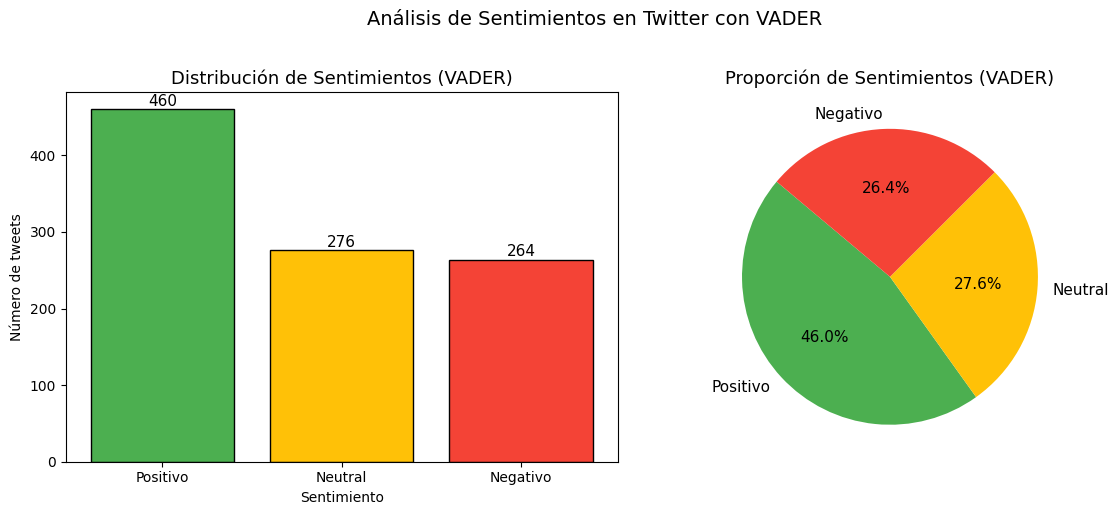

In [39]:
# Gráficos
conteo = df_resultados['sentimiento'].value_counts()
colores = {'Positivo': '#4CAF50', 'Neutral': '#FFC107', 'Negativo': '#F44336'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de barras
bars = axes[0].bar(
    conteo.index,
    conteo.values,
    color=[colores.get(s, 'gray') for s in conteo.index],
    edgecolor='black'
)
axes[0].set_title('Distribución de Sentimientos (VADER)', fontsize=13)
axes[0].set_xlabel('Sentimiento')
axes[0].set_ylabel('Número de tweets')

for bar, val in zip(bars, conteo.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max(conteo.values) * 0.01),
                 str(val), ha='center', fontsize=11)

# Gráfico de pastel
axes[1].pie(
    conteo.values,
    labels=conteo.index,
    colors=[colores.get(s, 'gray') for s in conteo.index],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 11}
)
axes[1].set_title('Proporción de Sentimientos (VADER)', fontsize=13)

plt.suptitle('Análisis de Sentimientos en Twitter con VADER', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()